In [1]:
import json
import re
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm.auto import tqdm

PROJECT_ROOT = next(
    path for path in (Path.cwd(), Path.cwd().parent)
    if (path / "data" / "manifests").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
FEAT_DIR = PROJECT_ROOT / "data" / "features"
FIG_DIR = PROJECT_ROOT / "data" / "figures"
FEAT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Feature cache:", FEAT_DIR)
print("Figures:", FIG_DIR)

c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Project: c:\Capstone
Feature cache: c:\Capstone\data\features
Figures: c:\Capstone\data\figures


## 1. Exploratory data analysis

In [2]:
train_df = pd.read_csv(PROJECT_ROOT / "data" / "manifests" / "train.csv")
val_df = pd.read_csv(PROJECT_ROOT / "data" / "manifests" / "val.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data" / "manifests" / "test.csv")

for split_name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{split_name}: {len(frame):,} images")
    print(frame["class"].value_counts().sort_index().to_string())
    print()

print("Manifest columns:", train_df.columns.tolist())
print("Training rows with missing values:", int(train_df.isna().sum().sum()))
for split_name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    pct = (frame["class"].value_counts(normalize=True) * 100).round(1)
    print(f"{split_name} class balance (%): {pct.to_dict()}")

for split_name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    missing = int((~frame["path"].map(lambda p: Path(p).exists())).sum())
    print(f"{split_name}: {missing} missing image files, "
          f"{int(frame['path'].duplicated().sum())} duplicate paths")

print("Image paths shared between splits:",
      len(set(train_df["path"]) & set(val_df["path"])),
      len(set(train_df["path"]) & set(test_df["path"])),
      len(set(val_df["path"]) & set(test_df["path"])))

Train: 5,686 images
class
ALL    3852
HEM    1834

Validation: 1,422 images
class
ALL    963
HEM    459

Test: 3,553 images
class
ALL    2457
HEM    1096

Manifest columns: ['path', 'label', 'class', 'fold']
Training rows with missing values: 0
Train class balance (%): {'ALL': 67.7, 'HEM': 32.3}
Validation class balance (%): {'ALL': 67.7, 'HEM': 32.3}
Test class balance (%): {'ALL': 69.2, 'HEM': 30.8}
Train: 0 missing image files, 0 duplicate paths
Validation: 0 missing image files, 0 duplicate paths
Test: 0 missing image files, 0 duplicate paths
Image paths shared between splits: 0 0 0


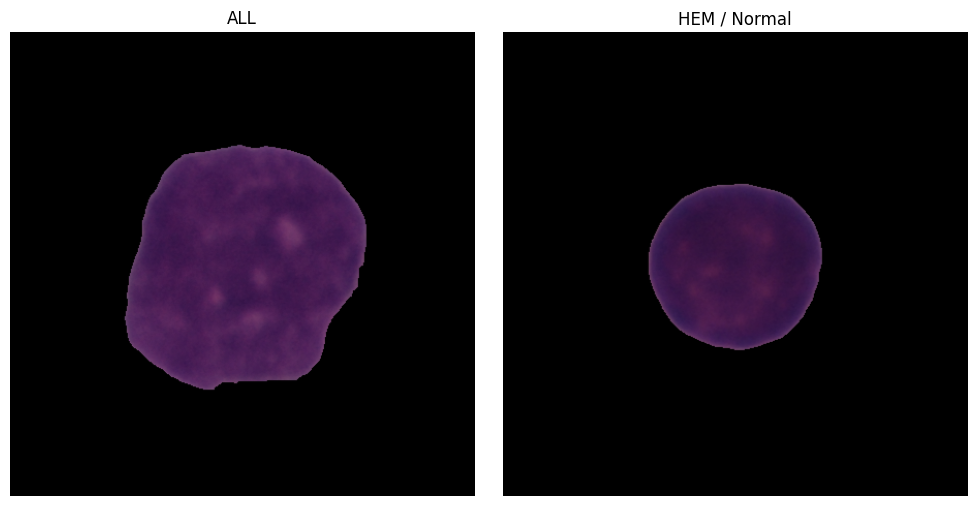

Sample image: C:\Users\DELL\Downloads\C-NMC 2019 (PKG)\C-NMC_training_data\fold_0\hem\UID_H24_36_5_hem.bmp
Dimensions: (450, 450) mode: RGB


In [3]:
all_sample = train_df.loc[train_df["class"] == "ALL"].iloc[0]
hem_sample = train_df.loc[train_df["class"] == "HEM"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, row, label in zip(axes, [all_sample, hem_sample], ["ALL", "HEM / Normal"]):
    with Image.open(row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(label)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_ALL_vs_HEM.png", dpi=200, bbox_inches="tight")
plt.show()

sample_path = train_df.iloc[0]["path"]
with Image.open(sample_path) as image:
    print("Sample image:", sample_path)
    print("Dimensions:", image.size, "mode:", image.mode)



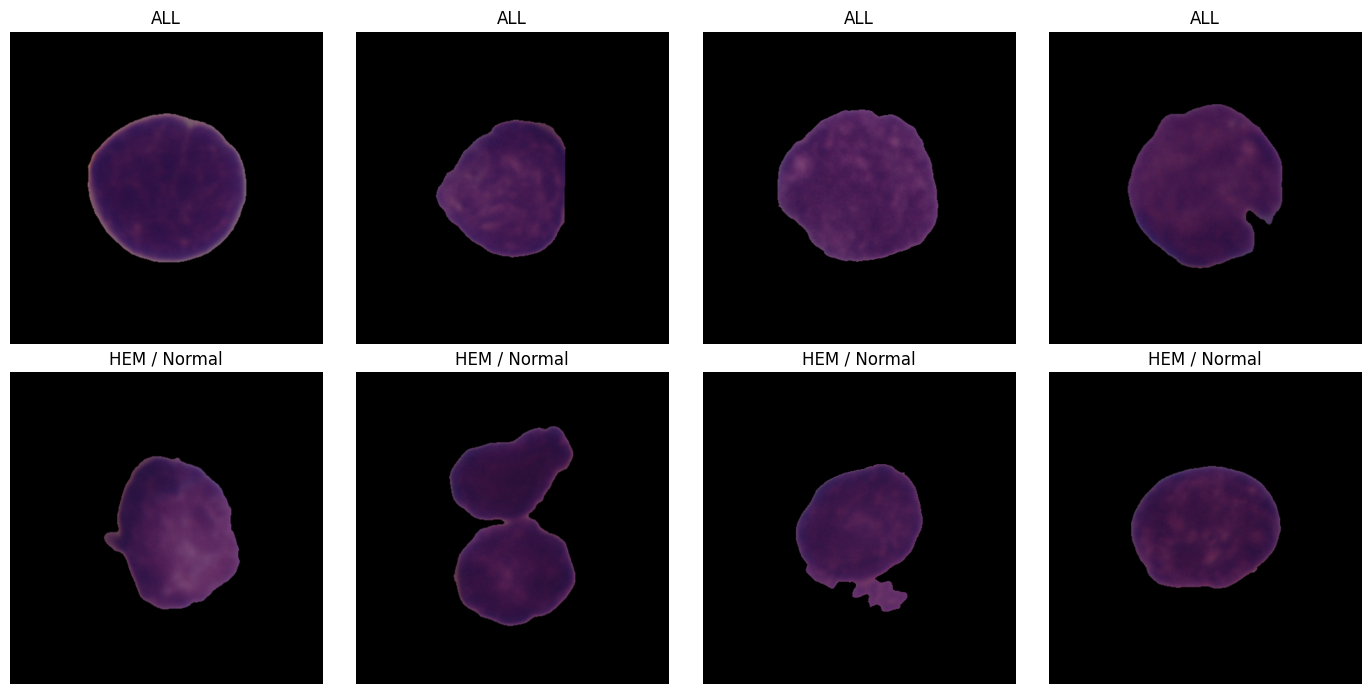

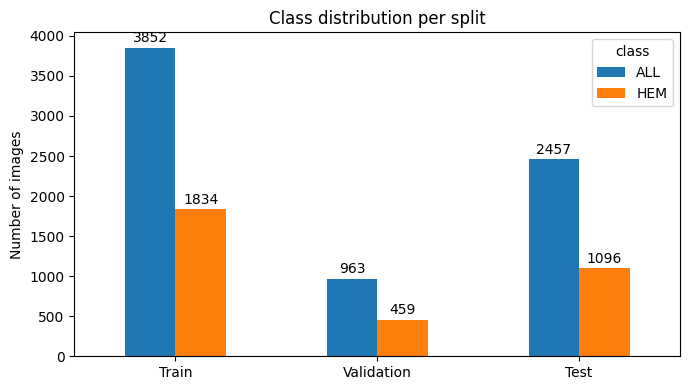

In [5]:
# Several random examples per class (fixed seed so the figure is reproducible)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row_axes, (class_name, title) in zip(axes, [("ALL", "ALL"), ("HEM", "HEM / Normal")]):
    samples = train_df.loc[train_df["class"] == class_name].sample(4, random_state=42)
    for ax, (_, row) in zip(row_axes, samples.iterrows()):
        with Image.open(row["path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(title)
        ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "samples_grid_ALL_vs_HEM.png", dpi=200, bbox_inches="tight")
plt.show()

# Class distribution per split
counts = pd.DataFrame({
    "Train": train_df["class"].value_counts(),
    "Validation": val_df["class"].value_counts(),
    "Test": test_df["class"].value_counts(),
}).T
ax = counts.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Number of images")
ax.set_title("Class distribution per split")
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
from collections import Counter

for split_name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    sizes, modes = Counter(), Counter()
    for image_path in frame["path"]:
        with Image.open(image_path) as image:
            sizes[image.size] += 1
            modes[image.mode] += 1
    print(f"{split_name}: sizes = {dict(sizes)}, modes = {dict(modes)}")

Train: sizes = {(450, 450): 5686}, modes = {'RGB': 5686}
Validation: sizes = {(450, 450): 1422}, modes = {'RGB': 1422}
Test: sizes = {(450, 450): 3553}, modes = {'RGB': 3553}


## 2. Optional preprocessing demo: Reinhard normalization

This is a visual demonstration only; the feature-extraction pipeline below uses BiomedCLIP's standard validation preprocessing.

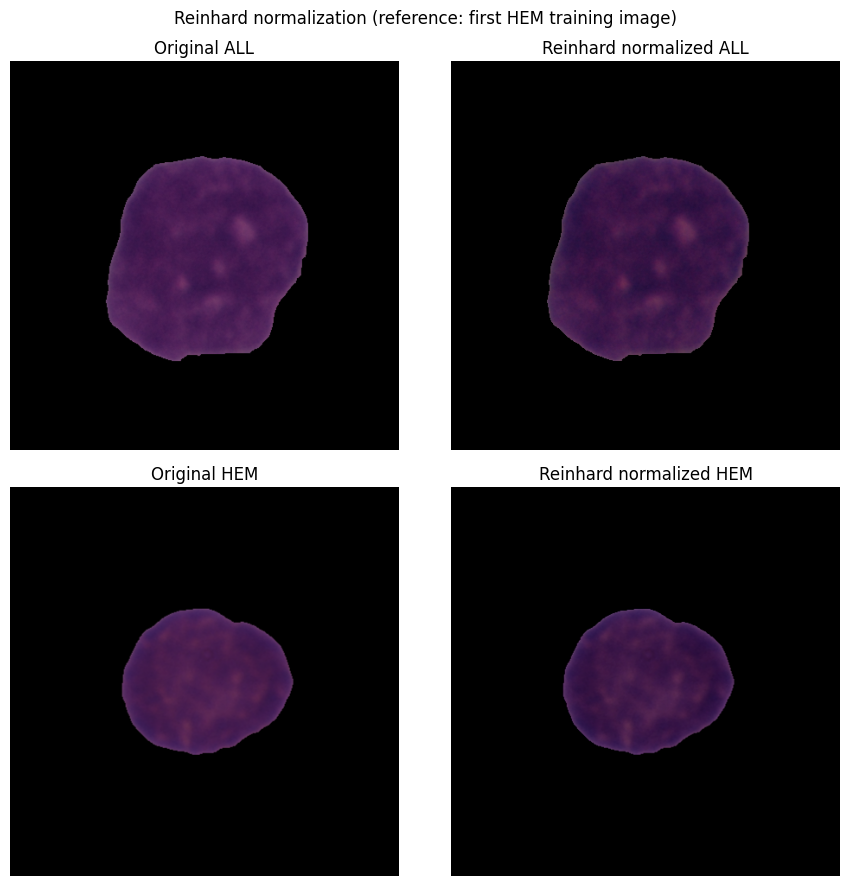

In [7]:
from src.preprocessing import reinhard_normalization

reference_path = train_df.loc[train_df["label"] == 0, "path"].iloc[0]
with Image.open(reference_path) as image:
    reference_image = image.convert("RGB")

examples = [
    ("ALL", train_df.loc[train_df["label"] == 1, "path"].iloc[0]),
    ("HEM", train_df.loc[train_df["label"] == 0, "path"].iloc[1]),  # [1], since [0] is the reference
]

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for row, (class_name, path) in enumerate(examples):
    with Image.open(path) as image:
        original = image.convert("RGB")
    normalized = reinhard_normalization(original, reference_image)
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Original {class_name}")
    axes[row, 1].imshow(normalized)
    axes[row, 1].set_title(f"Reinhard normalized {class_name}")
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Reinhard normalization (reference: first HEM training image)")
fig.tight_layout()
fig.savefig(FIG_DIR / "reinhard_demo.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Load the BiomedCLIP model once

In [8]:
MODEL_NAME = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, _, preprocess_val = open_clip.create_model_and_transforms(MODEL_NAME)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model = model.to(device).eval()
print("BiomedCLIP loaded on", device)


BiomedCLIP loaded on cpu


## 4. Extract and cache train, validation, and test features

In [ ]:
class ManifestImageDataset(Dataset):
    def __init__(self, frame, preprocess):
        self.frame = frame.reset_index(drop=True)
        self.preprocess = preprocess

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["path"]) as image:
            tensor = self.preprocess(image.convert("RGB"))
        return tensor, int(row["label"])


@torch.inference_mode()
def extract_cached_features(split_name, frame, batch_size=32, checkpoint_every=10):
    feature_path = FEAT_DIR / f"{split_name}_features.npy"
    label_path = FEAT_DIR / f"{split_name}_labels.npy"
    partial_feature_path = FEAT_DIR / f"{split_name}_partial_features.npy"
    partial_label_path = FEAT_DIR / f"{split_name}_partial_labels.npy"
    expected_labels = frame["label"].to_numpy(dtype=np.int64)

    if feature_path.exists() != label_path.exists():
        raise FileNotFoundError(f"Incomplete {split_name} feature cache in {FEAT_DIR}")
    if feature_path.exists():
        features = np.load(feature_path)
        labels = np.load(label_path).astype(np.int64)
        if len(features) != len(frame) or not np.array_equal(labels, expected_labels):
            raise ValueError(f"Cached {split_name} features do not match the manifest order")
        print(f"{split_name}: loaded cache {features.shape}")
        return features, labels

    if partial_feature_path.exists() != partial_label_path.exists():
        raise FileNotFoundError(f"Incomplete {split_name} extraction checkpoint in {FEAT_DIR}")
    if partial_feature_path.exists():
        features = list(np.load(partial_feature_path))
        labels = list(np.load(partial_label_path).astype(np.int64))
        if len(features) != len(labels) or len(labels) > len(frame):
            raise ValueError(f"Invalid {split_name} extraction checkpoint")
        if not np.array_equal(np.asarray(labels), expected_labels[:len(labels)]):
            raise ValueError(f"{split_name} checkpoint labels do not match the manifest order")
        print(f"{split_name}: resuming at image {len(labels)}")
    else:
        features, labels = [], []

    remaining = frame.iloc[len(labels):].reset_index(drop=True)
    loader = DataLoader(
        ManifestImageDataset(remaining, preprocess_val),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )
    model.eval()
    for batch_number, (images, batch_labels) in enumerate(
        tqdm(loader, desc=f"Extracting {split_name}"), start=1
    ):
        embeddings = model.encode_image(images.to(device)).float()
        embeddings = embeddings / embeddings.norm(dim=-1, keepdim=True).clamp(min=1e-12)
        features.extend(embeddings.cpu().numpy())
        labels.extend(batch_labels.numpy().astype(np.int64))
        if batch_number % checkpoint_every == 0:
            np.save(partial_feature_path, np.asarray(features, dtype=np.float32))
            np.save(partial_label_path, np.asarray(labels, dtype=np.int64))

    features = np.asarray(features, dtype=np.float32)
    labels = np.asarray(labels, dtype=np.int64)
    np.save(feature_path, features)
    np.save(label_path, labels)
    partial_feature_path.unlink(missing_ok=True)
    partial_label_path.unlink(missing_ok=True)
    print(f"{split_name}: saved {features.shape} to {FEAT_DIR}")
    return features, labels


train_features, train_labels = extract_cached_features("train", train_df)
val_features, val_labels = extract_cached_features("val", val_df)
test_features, test_labels = extract_cached_features("test", test_df)


train: loaded cache (5686, 512)
val: loaded cache (1422, 512)


Extracting test:   0%|          | 0/112 [00:00<?, ?it/s]

## 5. Subject-overlap leakage check

In [149]:
def subject_id(image_path):
    match = re.match(r"UID_([^_]+)_", Path(image_path).stem)
    if match is None:
        raise ValueError(f"Could not parse subject ID from {image_path}")
    return match.group(1)


splits = {"train": train_df, "validation": val_df, "test": test_df}
subject_sets = {
    name: set(frame["path"].map(subject_id)) for name, frame in splits.items()
}

print("Subjects and images per ORIGINAL manifest split:")
for name, frame in splits.items():
    subjects = frame["path"].map(subject_id)
    per_class = subjects.groupby(frame["class"]).nunique()
    print(
        f"  {name:<10} {subjects.nunique():>3} subjects "
        f"(ALL: {per_class.get('ALL', 0)}, HEM: {per_class.get('HEM', 0)}), "
        f"{len(frame):,} images"
    )
print()

for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = sorted(subject_sets[left] & subject_sets[right])
    print(f"{left} / {right}: {len(overlap)} overlapping subjects")
    if overlap:
        print("  WARNING: review possible subject leakage")
        print("  IDs:", ", ".join(overlap))

print(
    "\nNote: train/validation overlap in the original manifests is expected here. "
    "Section 6 pools train+validation and re-splits them by subject. "
    "The test set must have 0 overlap with both."
)

# Stop the notebook if the test set shares any subject with train or validation
assert not (subject_sets["train"] & subject_sets["test"]), "Test shares subjects with train"
assert not (subject_sets["validation"] & subject_sets["test"]), "Test shares subjects with validation"

Subjects and images per ORIGINAL manifest split:
  train       42 subjects (ALL: 30, HEM: 12), 5,686 images
  validation  42 subjects (ALL: 30, HEM: 12), 1,422 images
  test        31 subjects (ALL: 17, HEM: 14), 3,553 images

train / validation: 42 overlapping subjects
  IDs: 1, 11, 14, 15, 16, 17, 19, 2, 20, 22, 23, 26, 28, 3, 30, 32, 33, 34, 35, 38, 4, 43, 44, 45, 46, 48, 5, 50, 51, 52, H10, H11, H12, H14, H15, H16, H17, H19, H22, H24, H6, H7
train / test: 0 overlapping subjects
validation / test: 0 overlapping subjects

Note: train/validation overlap in the original manifests is expected here. Section 6 pools train+validation and re-splits them by subject. The test set must have 0 overlap with both.


## 6. Train balanced Logistic Regression and MLP classifiers

In [150]:
# --- Subject-disjoint re-split of the saved features (fixes train/val leakage) ---
pool_df = pd.concat([train_df, val_df], ignore_index=True)
X_pool = np.concatenate([train_features, val_features])
y_pool = np.concatenate([train_labels, val_labels]).astype(np.int64)
groups = pool_df["path"].map(subject_id).to_numpy()

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(splitter.split(X_pool, y_pool, groups))
assert not set(groups[train_idx]) & set(groups[val_idx]), "subject leakage between train and val"

X_train, y_train = X_pool[train_idx], y_pool[train_idx]
X_val, y_val = X_pool[val_idx], y_pool[val_idx]
X_test, y_test = test_features, test_labels.astype(np.int64)
print("Train:", len(y_train), np.bincount(y_train), "| Val:", len(y_val), np.bincount(y_val))

# --- Logistic regression (C tuned on the clean validation set) ---
best_C = max([0.1, 1, 10, 100, 1000], key=lambda C: roc_auc_score(
    y_val, LogisticRegression(C=C, max_iter=5000, class_weight="balanced")
           .fit(X_train, y_train).predict_proba(X_val)[:, 1]))
print("Best C:", best_C)
lr_model = LogisticRegression(C=best_C, max_iter=5000, class_weight="balanced", random_state=42)
lr_model.fit(X_train, y_train)

# --- MLP ---
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1),
        )

    def forward(self, features):
        return self.network(features).squeeze(1)


torch.manual_seed(42)
mlp_model = MLP(X_train.shape[1]).to(device)
train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                  torch.tensor(y_train, dtype=torch.float32)),
    batch_size=256, shuffle=True,
)
class_counts = np.bincount(y_train, minlength=2)
pos_weight = torch.tensor([class_counts[0] / class_counts[1]], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)

for epoch in range(15):
    mlp_model.train()
    total_loss = 0.0
    for batch_features, batch_labels in train_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
        optimizer.zero_grad()
        loss = criterion(mlp_model(batch_features), batch_labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch + 1:02d}/15 - loss: {total_loss / len(train_loader):.4f}")


# --- Threshold chosen on validation by balanced accuracy (not majority-class F1) ---
def validation_threshold(labels, probabilities):
    thresholds = np.linspace(0.05, 0.95, 91)
    return max(thresholds, key=lambda t: (
        balanced_accuracy_score(labels, (probabilities >= t).astype(int)),
        -abs(t - 0.5)))


lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
mlp_model.eval()
with torch.inference_mode():
    mlp_val_probs = torch.sigmoid(
        mlp_model(torch.tensor(X_val, dtype=torch.float32, device=device))
    ).cpu().numpy()
lr_threshold = float(validation_threshold(y_val, lr_val_probs))
mlp_threshold = float(validation_threshold(y_val, mlp_val_probs))
print(f"Validation-selected thresholds: LogReg {lr_threshold:.2f}, MLP {mlp_threshold:.2f}")

joblib.dump(lr_model, FEAT_DIR / "logreg_baseline.joblib")
torch.save(mlp_model.cpu().state_dict(), FEAT_DIR / "mlp_baseline.pth")
mlp_model = mlp_model.to(device)

Train: 5003 [1890 3113] | Val: 2105 [ 403 1702]
Best C: 10
Epoch 01/15 - loss: 0.5063
Epoch 02/15 - loss: 0.4661
Epoch 03/15 - loss: 0.4303
Epoch 04/15 - loss: 0.4159
Epoch 05/15 - loss: 0.4093
Epoch 06/15 - loss: 0.4057
Epoch 07/15 - loss: 0.3975
Epoch 08/15 - loss: 0.3926
Epoch 09/15 - loss: 0.3869
Epoch 10/15 - loss: 0.3842
Epoch 11/15 - loss: 0.3780
Epoch 12/15 - loss: 0.3744
Epoch 13/15 - loss: 0.3703
Epoch 14/15 - loss: 0.3672
Epoch 15/15 - loss: 0.3639
Validation-selected thresholds: LogReg 0.37, MLP 0.44


## 7. Evaluate: metrics, ROC curves, and confusion matrices

                     threshold  accuracy  precision  recall  specificity  balanced_accuracy      f1  roc_auc
Logistic Regression       0.37    0.7577     0.7868  0.8909       0.4589             0.6749  0.8357   0.7321
MLP                       0.44    0.7413     0.7727  0.8869       0.4151             0.6510  0.8258   0.7179


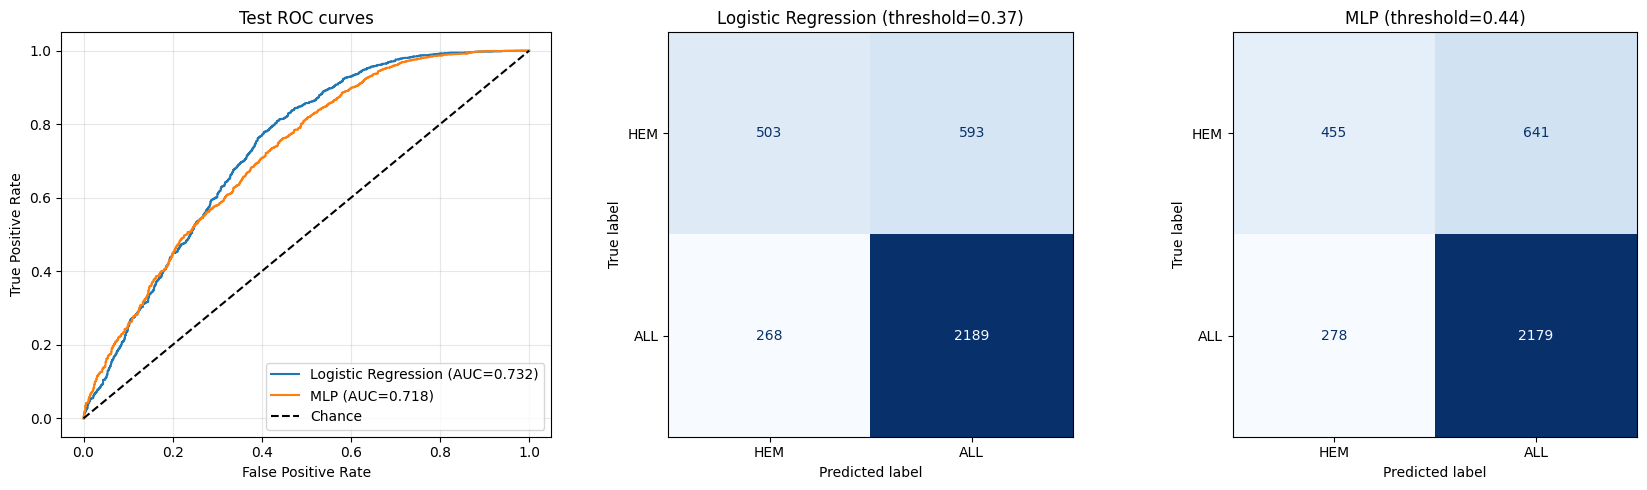

In [136]:
def binary_metrics(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(tn / (tn + fp)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "confusion_matrix": cm.tolist(),
    }


lr_test_probs = lr_model.predict_proba(X_test)[:, 1]
mlp_model.eval()
with torch.inference_mode():
    mlp_test_probs = torch.sigmoid(
        mlp_model(torch.tensor(X_test, dtype=torch.float32, device=device))
    ).cpu().numpy()

lr_results = binary_metrics(y_test, lr_test_probs, lr_threshold)
mlp_results = binary_metrics(y_test, mlp_test_probs, mlp_threshold)
(FEAT_DIR / "logreg_test_results.json").write_text(json.dumps(lr_results, indent=2))
(FEAT_DIR / "mlp_test_results.json").write_text(json.dumps(mlp_results, indent=2))
print(pd.DataFrame([lr_results, mlp_results], index=["Logistic Regression", "MLP"])[
    ["threshold", "accuracy", "precision", "recall", "specificity",
     "balanced_accuracy", "f1", "roc_auc"]
].round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name, probabilities in [("Logistic Regression", lr_test_probs), ("MLP", mlp_test_probs)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    score = roc_auc_score(y_test, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate, label=f"{name} (AUC={score:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Test ROC curves")
axes[0].legend()
axes[0].grid(alpha=0.3)
for ax, name, results in zip(axes[1:], ["Logistic Regression", "MLP"], [lr_results, mlp_results]):
    ConfusionMatrixDisplay(
        confusion_matrix=np.asarray(results["confusion_matrix"]),
        display_labels=["HEM", "ALL"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (threshold={results['threshold']:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_and_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Error analysis

                     threshold  accuracy  precision  recall  specificity  balanced_accuracy      f1  roc_auc
Logistic Regression       0.37    0.7577     0.7868  0.8909       0.4589             0.6749  0.8357   0.7321
MLP                       0.44    0.7413     0.7727  0.8869       0.4151             0.6510  0.8258   0.7179


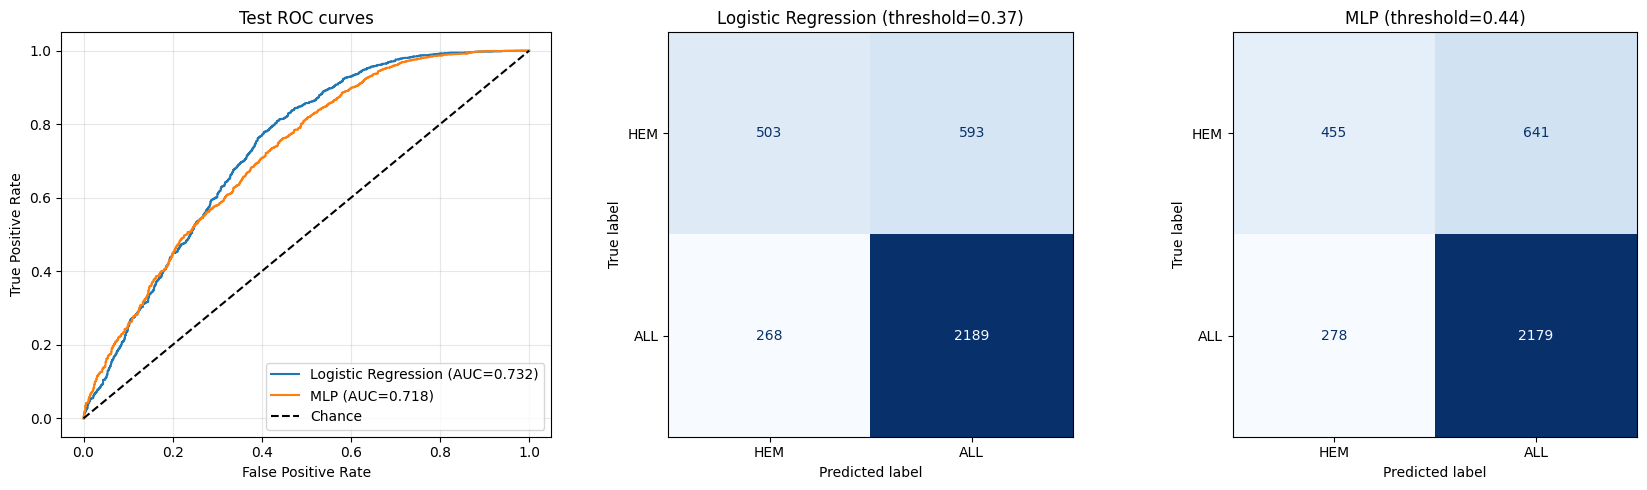

In [151]:
def binary_metrics(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(tn / (tn + fp)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "confusion_matrix": cm.tolist(),
    }


lr_test_probs = lr_model.predict_proba(X_test)[:, 1]
mlp_model.eval()
with torch.inference_mode():
    mlp_test_probs = torch.sigmoid(
        mlp_model(torch.tensor(X_test, dtype=torch.float32, device=device))
    ).cpu().numpy()

lr_results = binary_metrics(y_test, lr_test_probs, lr_threshold)
mlp_results = binary_metrics(y_test, mlp_test_probs, mlp_threshold)
(FEAT_DIR / "logreg_test_results.json").write_text(json.dumps(lr_results, indent=2))
(FEAT_DIR / "mlp_test_results.json").write_text(json.dumps(mlp_results, indent=2))
print(pd.DataFrame([lr_results, mlp_results], index=["Logistic Regression", "MLP"])[
    ["threshold", "accuracy", "precision", "recall", "specificity",
     "balanced_accuracy", "f1", "roc_auc"]
].round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name, probabilities in [("Logistic Regression", lr_test_probs), ("MLP", mlp_test_probs)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    score = roc_auc_score(y_test, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate, label=f"{name} (AUC={score:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Test ROC curves")
axes[0].legend()
axes[0].grid(alpha=0.3)
for ax, name, results in zip(axes[1:], ["Logistic Regression", "MLP"], [lr_results, mlp_results]):
    ConfusionMatrixDisplay(
        confusion_matrix=np.asarray(results["confusion_matrix"]),
        display_labels=["HEM", "ALL"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (threshold={results['threshold']:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_and_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

Misclassified: 919 / 3,553
error_type
False Positive    641
False Negative    278


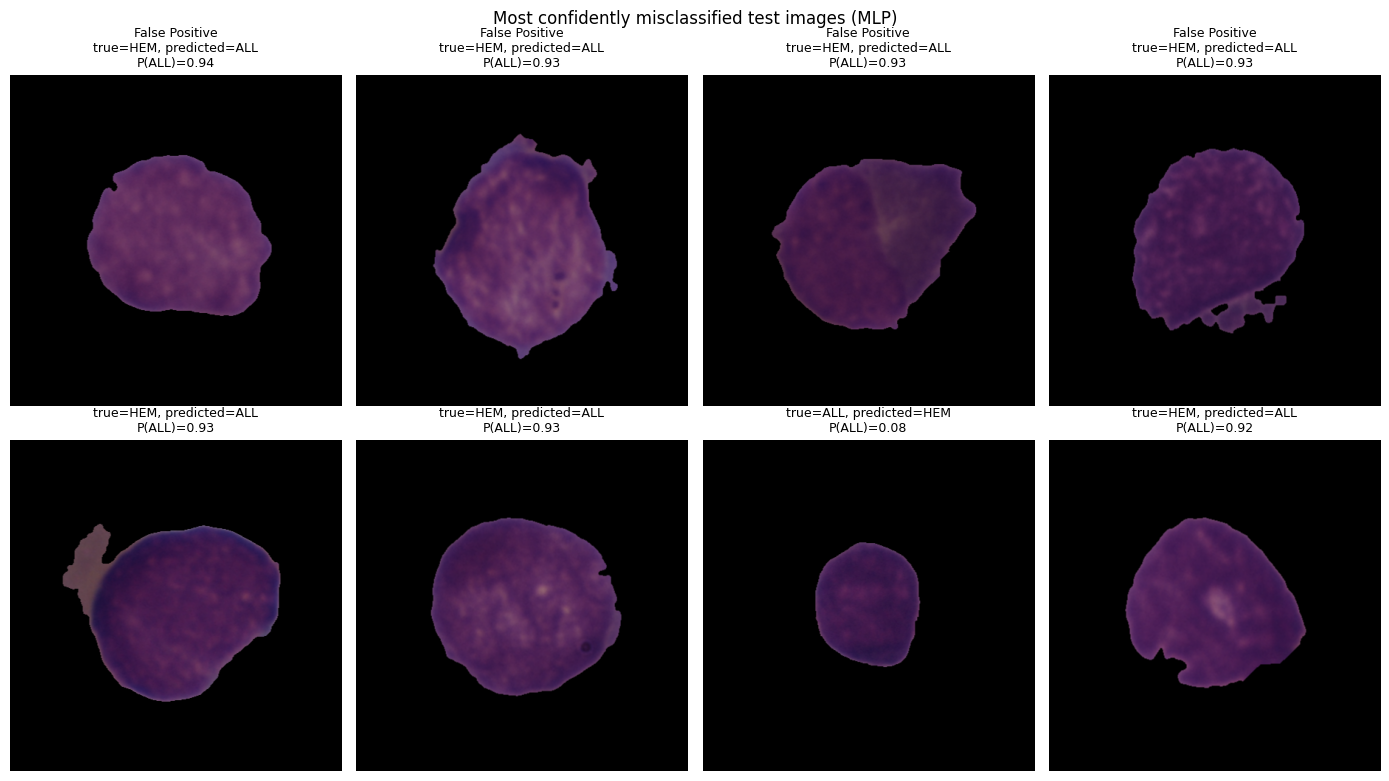

In [152]:
if len(test_df) != len(y_test):
    raise ValueError("test manifest and cached test labels have different lengths")

errors = test_df.copy()
errors["true_label"] = y_test
errors["pred_label"] = (mlp_test_probs >= mlp_threshold).astype(int)
errors["prob_all"] = mlp_test_probs
errors["error_type"] = np.where(
    (errors["true_label"] == 0) & (errors["pred_label"] == 1),
    "False Positive",
    np.where(
        (errors["true_label"] == 1) & (errors["pred_label"] == 0),
        "False Negative",
        "Correct",
    ),
)
errors = errors.loc[errors["error_type"] != "Correct"].copy()
errors["wrong_confidence"] = np.where(
    errors["pred_label"] == 1, errors["prob_all"], 1 - errors["prob_all"]
)
errors = errors.sort_values("wrong_confidence", ascending=False)
errors.to_csv(FIG_DIR / "mlp_misclassified.csv", index=False)
print(f"Misclassified: {len(errors):,} / {len(test_df):,}")
print(errors["error_type"].value_counts().to_string())

examples = errors.head(8)
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, (_, row) in zip(axes.ravel(), examples.iterrows()):
    with Image.open(row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    true_class = "ALL" if row["true_label"] == 1 else "HEM"
    predicted_class = "ALL" if row["pred_label"] == 1 else "HEM"
    ax.set_title(
        f"{row['error_type']}\ntrue={true_class}, predicted={predicted_class}\nP(ALL)={row['prob_all']:.2f}",
        fontsize=9,
    )
    ax.axis("off")
for ax in axes.ravel()[len(examples):]:
    ax.axis("off")
fig.suptitle("Most confidently misclassified test images (MLP)")
fig.tight_layout()
fig.savefig(FIG_DIR / "mlp_error_examples.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Zero-shot BiomedCLIP with corrected class prompts

In [137]:
CLASS_PROMPTS = {
    0: [  # HEM / normal
        "a microscopic blood smear image of a normal hematopoietic cell",
        "a normal blood cell in a microscope image",
        "a healthy cell from a human bone marrow blood smear",
    ],
    1: [  # ALL
        "a microscopic blood smear image of an acute lymphoblastic leukemia cell",
        "an abnormal lymphoblast in a blood smear from a patient with ALL",
        "a leukemia cell from a human bone marrow smear under a microscope",
    ],
}

model.eval()
class_text_features = []
with torch.inference_mode():
    for label in (0, 1):
        tokens = tokenizer(CLASS_PROMPTS[label]).to(device)
        prompt_features = model.encode_text(tokens).float()
        prompt_features = prompt_features / prompt_features.norm(dim=-1, keepdim=True).clamp(min=1e-12)
        class_feature = prompt_features.mean(dim=0)
        class_text_features.append(class_feature / class_feature.norm().clamp(min=1e-12))
    class_text_features = torch.stack(class_text_features)
    image_features = torch.tensor(test_features, dtype=torch.float32, device=device)
    scale = model.logit_scale.exp().detach() if hasattr(model, "logit_scale") else torch.tensor(100.0, device=device)
    zero_shot_probabilities = torch.softmax(
        scale * image_features @ class_text_features.T, dim=1
    )[:, 1].cpu().numpy()

zero_shot_results = binary_metrics(y_test, zero_shot_probabilities, 0.5)
(FEAT_DIR / "zeroshot_test_results.json").write_text(json.dumps(zero_shot_results, indent=2))

zero_shot_metrics = {k: v for k, v in zero_shot_results.items() if k != "confusion_matrix"}
print(pd.DataFrame([zero_shot_metrics]).round(4).to_string(index=False))
print("confusion_matrix:", zero_shot_results["confusion_matrix"])

 threshold  accuracy  precision  recall  specificity  balanced_accuracy     f1  roc_auc
       0.5     0.396     0.6986  0.2226       0.7847             0.5037 0.3377   0.4967
confusion_matrix: [[860, 236], [1910, 547]]


## 10. Final summary table

                             accuracy  precision  recall  specificity  balanced_accuracy      f1  roc_auc
Majority class (always ALL)    0.6915     0.6915  1.0000       0.0000             0.5000  0.8176   0.5000
Zero-Shot BiomedCLIP           0.3960     0.6986  0.2226       0.7847             0.5037  0.3377   0.4967
Logistic Regression            0.7577     0.7868  0.8909       0.4589             0.6749  0.8357   0.7321
MLP                            0.7413     0.7727  0.8869       0.4151             0.6510  0.8258   0.7179


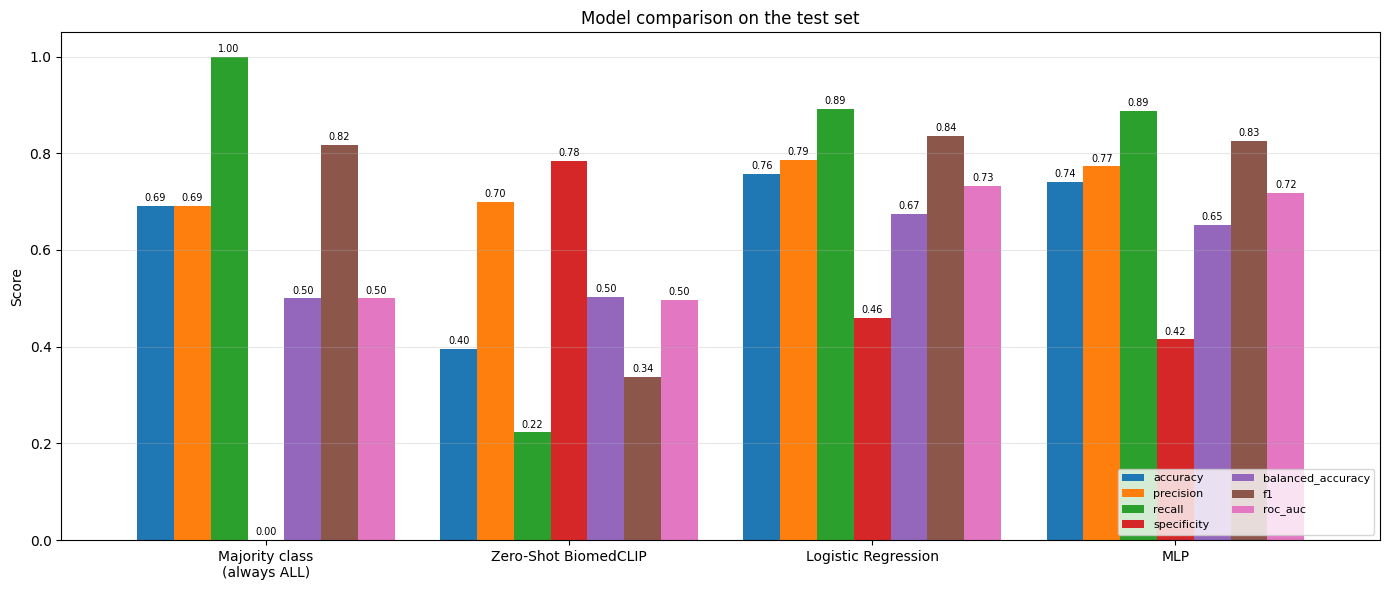

Saved summary to C:\Users\DELL\OneDrive\Desktop\Capstone\data\figures\final_results_summary.csv


In [153]:
results_by_model = {
    "Majority class (always ALL)": binary_metrics(y_test, np.ones(len(y_test)), 0.5),
    "Zero-Shot BiomedCLIP": zero_shot_results,
    "Logistic Regression": lr_results,
    "MLP": mlp_results,
}
metrics = ["accuracy", "precision", "recall", "specificity", "balanced_accuracy", "f1", "roc_auc"]
summary = pd.DataFrame(
    {name: {metric: values[metric] for metric in metrics}
     for name, values in results_by_model.items()}
).T.round(4)
summary_path = FIG_DIR / "final_results_summary.csv"
summary.to_csv(summary_path)
print(summary.to_string())

ax = summary.plot(kind="bar", figsize=(14, 6), width=0.85)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the test set")
ax.set_xticklabels([name.replace(" (", "\n(") for name in summary.index], rotation=0)
ax.legend(loc="lower right", ncol=2, fontsize=8)
ax.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "final_results_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved summary to", summary_path)